In [64]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
import torch
from torch import nn
import matplotlib.pyplot as plt
import time

In [65]:
df = pd.read_csv('./data/SMSSpamCollection', sep='\t', names=['type', 'message'])
df['spam'] = df['type'] == 'spam'
df = df.drop(columns=['type'])

cv = CountVectorizer(max_features=1000)
messages = cv.fit_transform(df['message'])

X = torch.tensor(
    messages.todense(), dtype=torch.float32
)
y = torch.tensor(
    df['spam'], dtype=torch.float32
).reshape((-1, 1))

print(X.shape, y.shape)

torch.Size([5572, 1000]) torch.Size([5572, 1])


In [66]:
model = nn.Linear(1000, 1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001)
losses = []

tensor(0.1602, grad_fn=<MseLossBackward0>)
tensor(0.1289, grad_fn=<MseLossBackward0>)
tensor(0.1127, grad_fn=<MseLossBackward0>)
tensor(0.1029, grad_fn=<MseLossBackward0>)
tensor(0.0960, grad_fn=<MseLossBackward0>)
tensor(0.0906, grad_fn=<MseLossBackward0>)
tensor(0.0861, grad_fn=<MseLossBackward0>)
tensor(0.0821, grad_fn=<MseLossBackward0>)
tensor(0.0786, grad_fn=<MseLossBackward0>)
tensor(0.0754, grad_fn=<MseLossBackward0>)
tensor(0.0726, grad_fn=<MseLossBackward0>)
tensor(0.0700, grad_fn=<MseLossBackward0>)
tensor(0.0676, grad_fn=<MseLossBackward0>)
tensor(0.0655, grad_fn=<MseLossBackward0>)
tensor(0.0635, grad_fn=<MseLossBackward0>)
tensor(0.0617, grad_fn=<MseLossBackward0>)
tensor(0.0601, grad_fn=<MseLossBackward0>)
tensor(0.0585, grad_fn=<MseLossBackward0>)
tensor(0.0571, grad_fn=<MseLossBackward0>)
tensor(0.0558, grad_fn=<MseLossBackward0>)
tensor(0.0546, grad_fn=<MseLossBackward0>)
tensor(0.0535, grad_fn=<MseLossBackward0>)
tensor(0.0524, grad_fn=<MseLossBackward0>)
tensor(0.05

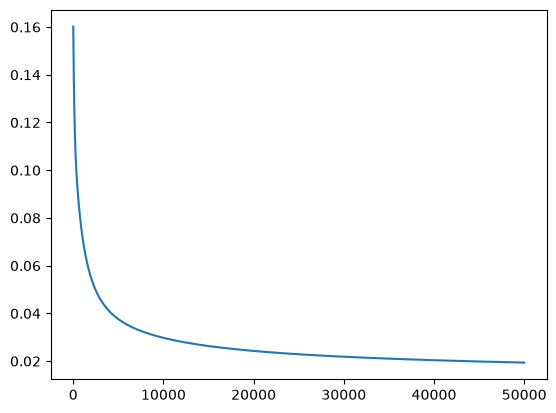

In [67]:
t_time = time.time()
for i in range(0, 50000):
    model.zero_grad()
    outputs = model(X)
    loss = loss_fn(outputs, y)
    loss.backward()
    optimizer.step()
    
    # if i % 100 == 0:
    #     print(loss)
    
    losses.append(loss.item())
e_time = time.time()
print(f'It taks {e_time - t_time} to finish!')
plt.plot(losses)
plt.show()

In [68]:
model.eval()

with torch.no_grad():
    y_pred = model(X)
    print(y_pred)
    print(y_pred.min())
    print(y_pred.max())

tensor([[ 0.0032],
        [ 0.0298],
        [ 1.0578],
        ...,
        [-0.0253],
        [ 0.1296],
        [-0.0104]])
tensor(-0.4450)
tensor(1.4799)


In [80]:
spam_pred = []
for i in range(len(y_pred)):
    # print(y_pred[i].numpy()[0])
    spam_pred.append(y_pred[i].numpy()[0])
spam_pred = pd.Series(spam_pred)
print(spam_pred)
df['spam_pred'] = spam_pred

0       0.003230
1       0.029817
2       1.057752
3      -0.019773
4       0.006774
          ...   
5567    0.963002
5568   -0.022074
5569   -0.025271
5570    0.129576
5571   -0.010404
Length: 5572, dtype: float32
